# 08 · Data Preparation & Exploratory Data Analysis (EDA)

Notebooks 01–07 used clean, ready-made datasets. Real data is never like that. Practitioners often say **most of the time on an ML project goes into understanding and cleaning data**, and that a simple model on well-prepared data beats a fancy model on messy data.

This notebook works on a realistic, deliberately messy table: **6,060 customers of a subscription business**. The task (used again in notebooks 09–11) is to predict which customers will **churn** (cancel).

**What you'll learn**
1. A first look: shapes, types, summary statistics, and how to spot problems
2. Cleaning: duplicates, numbers stored as text, inconsistent categories, impossible values, **leaky columns**
3. EDA: the target, distributions, relationships with the target, correlations
4. **Missing values:** why they're missing matters; imputation strategies
5. **Outliers:** detecting (IQR, z-score) and handling them
6. **Encoding categories:** one-hot, ordinal, and target encoding (with its leakage trap)
7. **Scaling:** standard, min-max, robust — and which models need it
8. **Feature engineering**
9. Packaging everything into a scikit-learn **Pipeline** that can't leak

As before, the core operations are shown 🐍 in pure Python → 🔢 with NumPy/pandas → 📦 with scikit-learn.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (5.5, 3.6)
plt.rcParams["axes.grid"] = True; plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)

from churn_utils import load_raw
raw = load_raw()          # reads data/customer_churn.csv (regenerates it if missing)
print(raw.shape)
raw.head()

(6060, 17)


,customer_id,signup_date,age,region,plan,contract,payment_method,has_partner,monthly_charges,tenure_months,total_charges,support_calls,avg_session_minutes,satisfaction_score,last_login_days_ago,cancellation_reason,churned
0,C104349,2022-05-30,49.0,west,standard,month-to-month,electronic check,no,64.19,31,1986.03,0,24.4,NaN,0,price,1
1,C101609,2021-07-04,NaN,WEST,standard,two-year,credit card,no,50.54,41,2069.93,0,18.7,3.0,17,NaN,0
2,C102094,2021-08-26,50.0,north,basic,two-year,credit card,no,38.16,40,1519.48,2,20.5,3.0,16,NaN,0
3,C102780,2022-03-31,46.0,north,basic,two-year,bank transfer,yes,35.78,33,1173.74,4,11.5,3.0,6,NaN,0
4,C104987,2024-09-10,41.0,NORTH,premium,two-year,electronic check,no,100.43,3,301.82,0,28.1,3.0,0,NaN,0


> **About the data.** It's synthetic, generated by `data/make_churn_data.py` to imitate a real customer table, including its problems. Because we know the true formula that decides who churns, notebooks 10 and 11 can check whether models and explanations recover the real drivers. Columns:
>
> `customer_id`, `signup_date`, `age`, `region`, `plan` (basic/standard/premium), `contract` (month-to-month / one-year / two-year), `payment_method`, `has_partner`, `monthly_charges`, `tenure_months` (how long they've been a customer), `total_charges`, `support_calls`, `avg_session_minutes`, `satisfaction_score` (1–5 survey), `last_login_days_ago`, `cancellation_reason`, and the target **`churned`** (1 = cancelled).

## 1. First look — ask the data questions

Before any modelling, answer: *How big is it? What type is each column? What's missing? Do the numbers make sense?*

In [2]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 6060 entries, 0 to 6059
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   customer_id          6060 non-null   str    
 1   signup_date          6060 non-null   str    
 2   age                  5866 non-null   float64
 3   region               6060 non-null   str    
 4   plan                 6060 non-null   str    
 5   contract             6060 non-null   str    
 6   payment_method       6060 non-null   str    
 7   has_partner          6060 non-null   str    
 8   monthly_charges      6060 non-null   float64
 9   tenure_months        6060 non-null   int64  
 10  total_charges        6060 non-null   str    
 11  support_calls        6060 non-null   int64  
 12  avg_session_minutes  5833 non-null   float64
 13  satisfaction_score   5288 non-null   float64
 14  last_login_days_ago  6060 non-null   int64  
 15  cancellation_reason  1690 non-null   str    
 16 

In [3]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
age,5866.0,43.320150,30.609553,18.0,34.00,42.000,51.00,999.00
monthly_charges,6060.0,58.677734,23.825417,-45.7,39.16,55.195,71.87,121.97
tenure_months,6060.0,23.555611,13.848449,0.0,11.00,24.000,36.00,47.00
support_calls,6060.0,1.557426,1.313471,0.0,1.00,1.000,2.00,9.00
avg_session_minutes,5833.0,26.038642,12.702227,1.3,16.90,24.300,33.10,103.80
satisfaction_score,5288.0,3.530068,0.892270,1.0,3.00,4.000,4.00,5.00
last_login_days_ago,6060.0,10.443894,11.502907,0.0,3.00,7.000,14.00,108.00
churned,6060.0,0.278878,0.448484,0.0,0.00,0.000,1.00,1.00


Already several problems are visible — this is what you train your eye to catch:

| Clue | Problem |
|---|---|
| `total_charges` has dtype **object** (text), not float | numbers stored as text — something non-numeric is in there |
| `age` max is **999** | impossible values (data-entry errors) |
| `monthly_charges` min is **negative** | sign errors |
| `satisfaction_score`, `age`, `avg_session_minutes` have fewer non-null rows | missing values |
| `cancellation_reason` is mostly null | suspicious — when is it filled in? |

In [4]:
for col in ["region", "plan", "contract", "payment_method", "has_partner"]:
    print(f"{col:15s}", raw[col].value_counts().to_dict())

region          {'north': 1694, 'east': 1409, 'south': 1386, 'west': 1094, 'NORTH': 86, 'EAST': 72, 'SOUTH': 68, 'WEST': 66, 'East ': 49, 'North ': 47, 'South ': 46, 'West ': 43}
plan            {'basic': 2707, 'standard': 2180, 'premium': 1173}
contract        {'month-to-month': 3357, 'one-year': 1536, 'two-year': 1167}
payment_method  {'credit card': 2103, 'electronic check': 1816, 'bank transfer': 1516, 'mailed check': 625}
has_partner     {'no': 3371, 'yes': 2689}


`region` has 12 spellings of 4 regions (`north`, `NORTH`, `North `…). A model would treat them as 12 different places.

## 2. Cleaning

### 2.1 Duplicate rows
Exports and joins often duplicate rows. Duplicates over-weight some customers and — worse — can land the *same* customer in both train and test, inflating scores.

In [5]:
# 🐍 Pure Python: a row is a duplicate if we've seen the exact same tuple of values before
def find_duplicates_python(rows):
    seen, dup_idx = set(), []
    for i, row in enumerate(rows):
        key = tuple(row)
        if key in seen:
            dup_idx.append(i)
        seen.add(key)
    return dup_idx

rows = raw.astype(str).values.tolist()
print("pure Python duplicates:", len(find_duplicates_python(rows)))

# 🔢 pandas
print("pandas duplicates:     ", raw.duplicated().sum())
print("duplicate customer_ids:", raw["customer_id"].duplicated().sum(), "(same customers → confirms these are export duplicates)")
df = raw.drop_duplicates().reset_index(drop=True)
print("rows after dropping:", len(df))

pure Python duplicates: 60
pandas duplicates:      60
duplicate customer_ids: 60 (same customers → confirms these are export duplicates)
rows after dropping: 6000


### 2.2 Numbers stored as text
Why is `total_charges` text? Let's find the values that won't convert.

In [6]:
# 🐍 Pure Python: try to convert, collect what fails
def find_non_numeric(values):
    bad = {}
    for v in values:
        try:
            float(v)
        except (ValueError, TypeError):
            bad[repr(v)] = bad.get(repr(v), 0) + 1
    return bad

print("values that aren't numbers:", find_non_numeric(df["total_charges"]))
print("their tenure_months:", df.loc[df["total_charges"].str.strip() == "", "tenure_months"].unique())

values that aren't numbers: {"' '": 135}
their tenure_months: [0]


They're blank strings `" "` — and every one belongs to a customer with **tenure 0** (just signed up, never billed). So the right fix isn't "unknown", it's **0**. Understanding *why* data is odd usually tells you how to fix it.

In [7]:
# 🔢 pandas: errors="coerce" turns anything unparseable into NaN, then we fill the explained case
df["total_charges"] = pd.to_numeric(df["total_charges"], errors="coerce")
df.loc[df["tenure_months"] == 0, "total_charges"] = 0.0
print("dtype now:", df["total_charges"].dtype, "| missing:", df["total_charges"].isna().sum())

dtype now: float64 | missing: 0


### 2.3 Inconsistent categories

In [8]:
# 🐍 Pure Python normalisation
def normalise_python(s):
    return s.strip().lower()
print([normalise_python(s) for s in ["NORTH", "North ", "north"]])

# 🔢 pandas: vectorised string methods with .str
df["region"] = df["region"].str.strip().str.lower()
print(df["region"].value_counts().to_dict())

['north', 'north', 'north']
{'north': 1810, 'east': 1512, 'south': 1487, 'west': 1191}


### 2.4 Impossible values
An age of 999 or a negative price isn't an "outlier" — it's an **error**. Don't delete the whole row (the other columns are fine); mark the bad value as **missing** and let imputation handle it later.

In [9]:
print("ages > 100:", (df["age"] > 100).sum(), "| negative charges:", (df["monthly_charges"] < 0).sum())
df.loc[(df["age"] < 18) | (df["age"] > 100), "age"] = np.nan
df.loc[df["monthly_charges"] < 0, "monthly_charges"] = np.nan

ages > 100: 5 | negative charges: 3


### 2.5 Leaky and useless columns — the most important check

Ask of every column: **"Would I know this value at the moment I need to make the prediction?"**

- `cancellation_reason` is filled in **only after** a customer cancels. A model would learn "reason is not empty → churned" and score ~100% in testing, then be useless in production, where the reason is always empty *before* churn. This is **target leakage**.
- `customer_id` is a label, not a property of the customer — a model could memorise it but it can't generalise.
- `signup_date` is already captured by `tenure_months`.

In [10]:
print(pd.crosstab(df["cancellation_reason"].notna(), df["churned"], rownames=["reason filled in?"]))
df = df.drop(columns=["cancellation_reason", "customer_id", "signup_date"])
print("\nremaining columns:", list(df.columns))

churned               0     1
reason filled in?            
False              4332     0
True                  0  1668

remaining columns: ['age', 'region', 'plan', 'contract', 'payment_method', 'has_partner', 'monthly_charges', 'tenure_months', 'total_charges', 'support_calls', 'avg_session_minutes', 'satisfaction_score', 'last_login_days_ago', 'churned']


## 3. Exploratory Data Analysis

### 3.1 The target
Always look at the target first: how balanced is it?

In [11]:
rate = df["churned"].mean()
print(f"churn rate: {rate:.1%}  → a model that always says 'no churn' would be {1 - rate:.1%} accurate. That's our floor to beat.")

churn rate: 27.8%  → a model that always says 'no churn' would be 72.2% accurate. That's our floor to beat.


### 3.2 Distributions of numeric features
Look for skew, spikes, strange gaps and remaining errors.

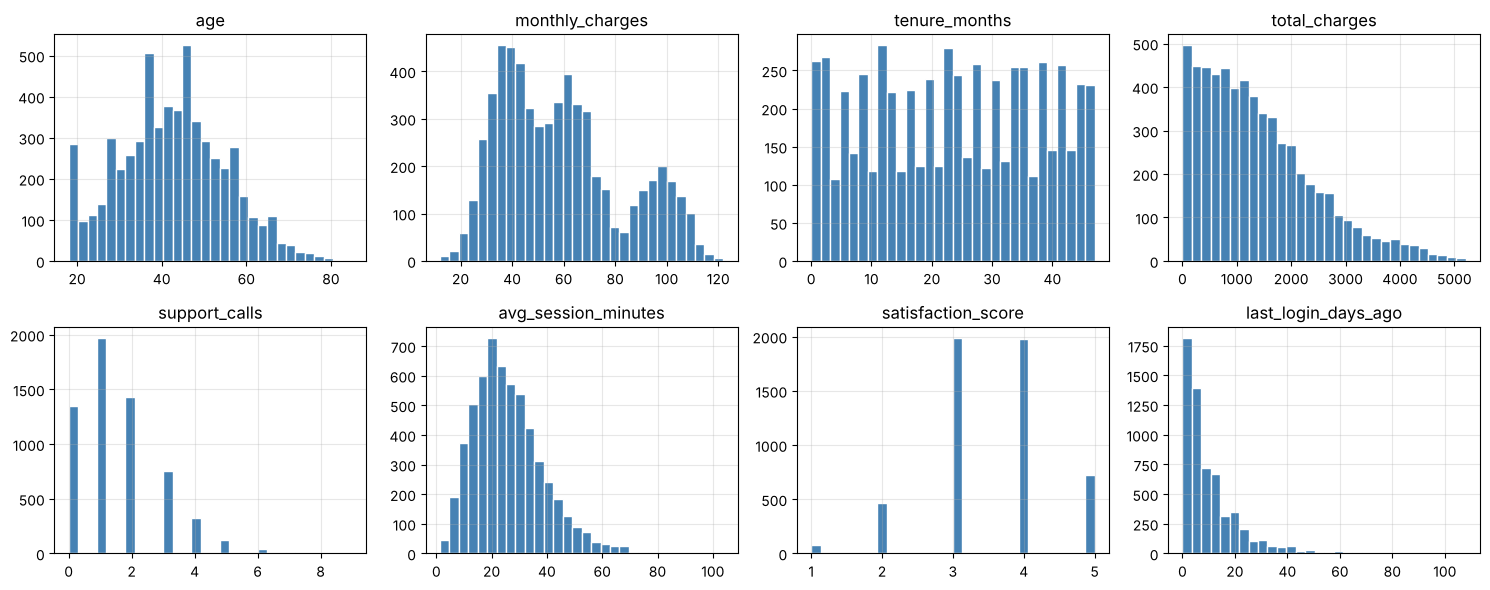

In [12]:
num_cols = ["age", "monthly_charges", "tenure_months", "total_charges", "support_calls",
            "avg_session_minutes", "satisfaction_score", "last_login_days_ago"]
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, c in zip(axes.ravel(), num_cols):
    ax.hist(df[c].dropna(), bins=30, color="steelblue", edgecolor="white"); ax.set_title(c)
plt.tight_layout(); plt.show()

Observations: `monthly_charges` has **three bumps** (one per plan); `last_login_days_ago` and `total_charges` are **right-skewed** (long tail); `support_calls` and `satisfaction_score` are small integers.

### 3.3 Features vs the target
The key EDA question: **which features differ between churners and non-churners?**

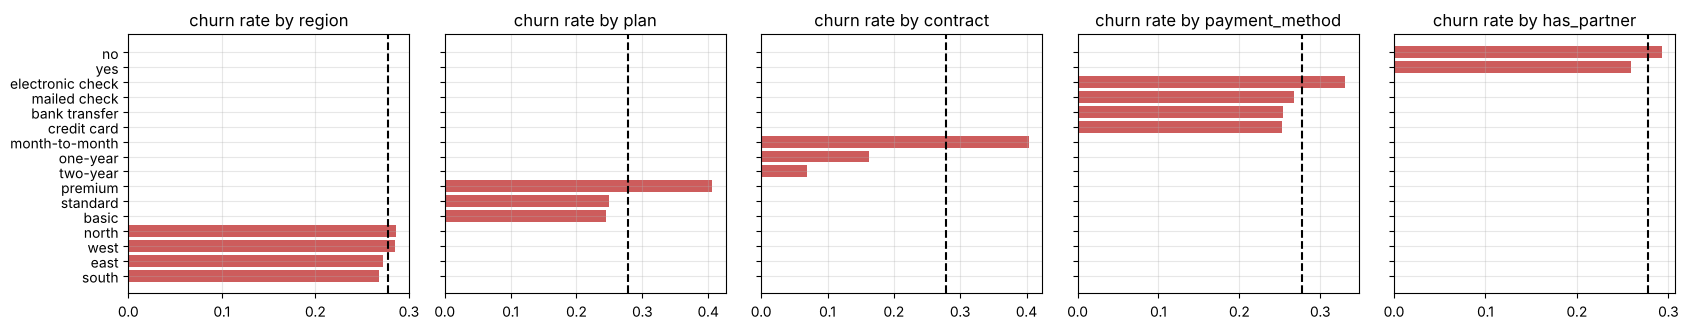

In [13]:
cat_cols = ["region", "plan", "contract", "payment_method", "has_partner"]
fig, axes = plt.subplots(1, 5, figsize=(17, 3.4), sharey=True)
for ax, c in zip(axes, cat_cols):
    r = df.groupby(c)["churned"].mean().sort_values()
    ax.barh(r.index, r.values, color="indianred"); ax.axvline(rate, ls="--", c="k"); ax.set_title(f"churn rate by {c}")
plt.tight_layout(); plt.show()

`contract` is a huge driver (month-to-month customers churn far more), `payment_method` matters (electronic check), `region` looks irrelevant. For numeric features, compare the two groups' distributions:

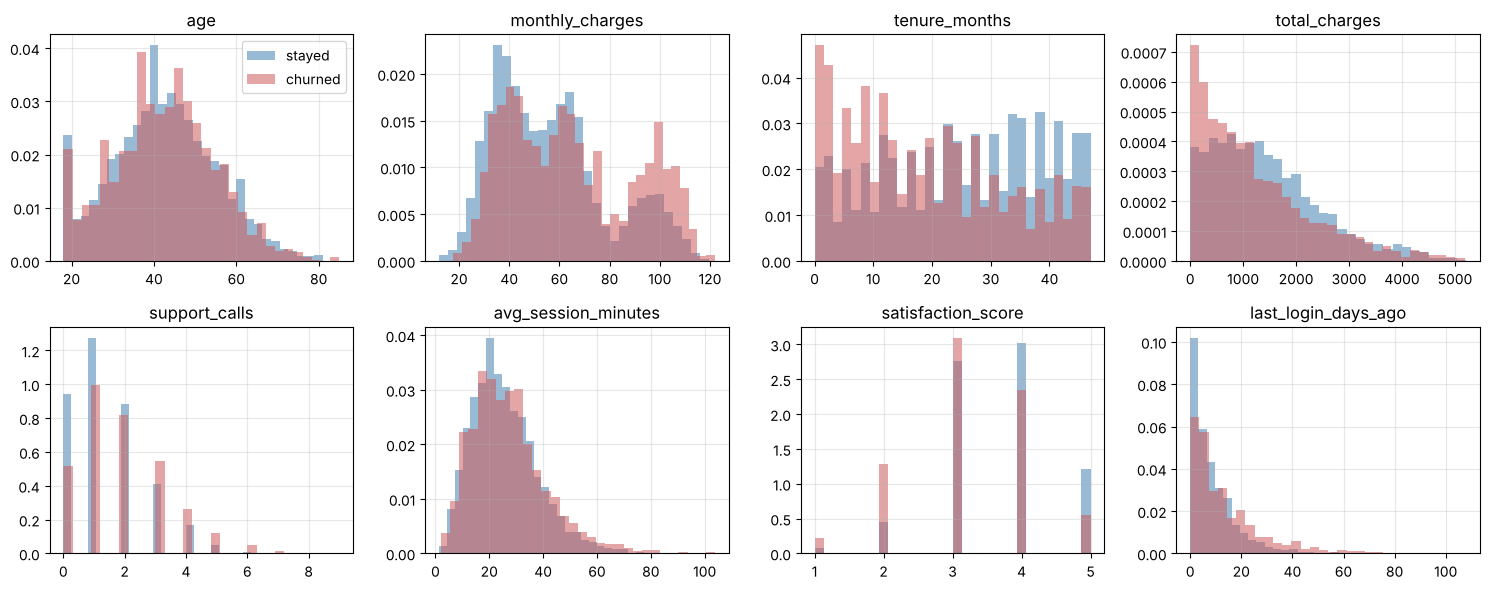

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, c in zip(axes.ravel(), num_cols):
    for label, colour in [(0, "steelblue"), (1, "indianred")]:
        ax.hist(df.loc[df["churned"] == label, c].dropna(), bins=30, alpha=0.55, density=True, color=colour,
                label="churned" if label else "stayed")
    ax.set_title(c)
axes[0, 0].legend(); plt.tight_layout(); plt.show()

**Binned rates** reveal shape that a correlation coefficient would hide. Churn falls steeply over the first ~3 years of tenure, then flattens — a **non-linear** effect (a straight-line model would mis-handle it; trees handle it naturally).

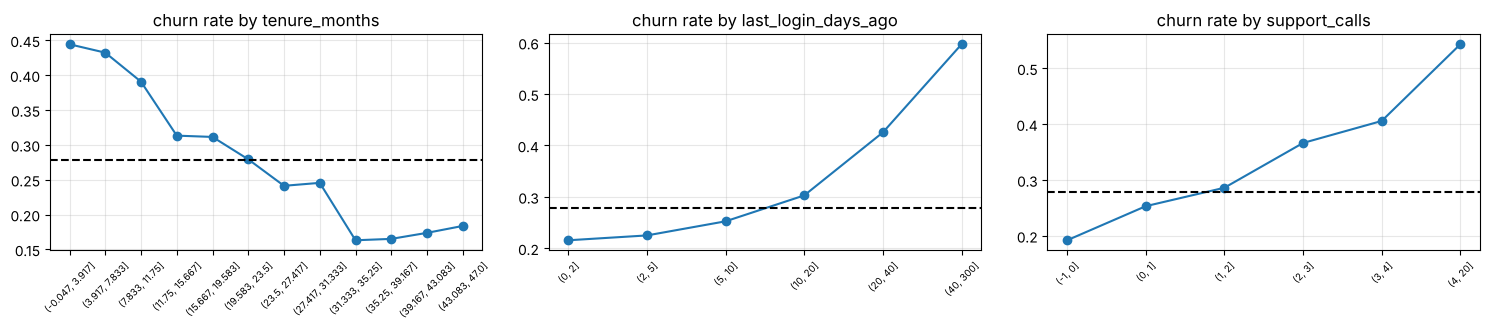

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
for ax, (c, bins) in zip(axes, [("tenure_months", 12), ("last_login_days_ago", [0, 2, 5, 10, 20, 40, 300]), ("support_calls", [-1, 0, 1, 2, 3, 4, 20])]):
    r = df.groupby(pd.cut(df[c], bins), observed=True)["churned"].mean()
    ax.plot(range(len(r)), r.values, "o-"); ax.set_xticks(range(len(r))); ax.set_xticklabels([str(i) for i in r.index], rotation=45, fontsize=7)
    ax.set_title(f"churn rate by {c}"); ax.axhline(rate, ls="--", c="k")
plt.tight_layout(); plt.show()

### 3.4 Correlations
The **Pearson correlation** $r \in [-1, 1]$ measures how well two variables fit a *straight line* together:
$$ r = \frac{\sum (x_i - \bar x)(y_i - \bar y)}{\sqrt{\sum (x_i - \bar x)^2}\sqrt{\sum (y_i - \bar y)^2}} $$
Use it to spot **redundant features** (two features with |r| ≈ 1 carry the same information) — but remember it misses non-linear relationships.

tenure vs total_charges — pure Python r = 0.782, pandas r = 0.782


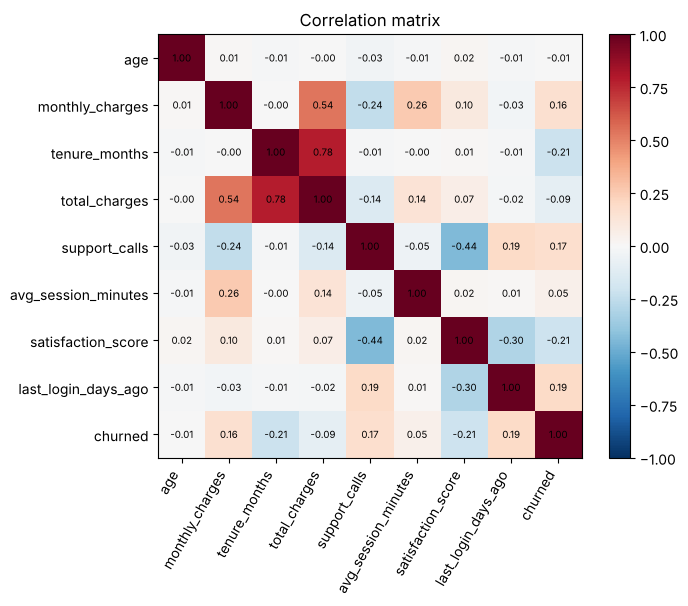

In [16]:
# 🐍 Pure Python correlation
def pearson_python(x, y):
    pairs = [(a, b) for a, b in zip(x, y) if a == a and b == b]          # skip NaN (NaN != NaN)
    n = len(pairs); mx = sum(a for a, _ in pairs) / n; my = sum(b for _, b in pairs) / n
    cov = sum((a - mx) * (b - my) for a, b in pairs)
    sx = sum((a - mx) ** 2 for a, _ in pairs) ** 0.5; sy = sum((b - my) ** 2 for _, b in pairs) ** 0.5
    return cov / (sx * sy)

print(f"tenure vs total_charges — pure Python r = {pearson_python(df['tenure_months'], df['total_charges']):.3f}, "
      f"pandas r = {df['tenure_months'].corr(df['total_charges']):.3f}")

corr = df[num_cols + ["churned"]].corr()
plt.figure(figsize=(7, 5.5))
plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1); plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=60, ha="right"); plt.yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.title("Correlation matrix"); plt.grid(False); plt.show()

`total_charges` ≈ `monthly_charges × tenure`, so it's strongly correlated with tenure — partly redundant. `support_calls` and `satisfaction_score` are negatively correlated (more calls → less happy).

## 4. Missing values

### 4.1 First ask *why* it's missing
| Type | Meaning | Example |
|---|---|---|
| **MCAR** — missing completely at random | unrelated to anything | a sensor randomly drops readings |
| **MAR** — missing at random | depends on *other observed* columns | older customers skip an online form more |
| **MNAR** — missing not at random | depends on the *missing value itself* | unhappy customers don't answer a satisfaction survey |

If missingness is informative, the fact that a value is missing **is a feature**. Check: does the target rate differ when a value is missing?

In [17]:
for c in ["satisfaction_score", "age", "avg_session_minutes"]:
    miss = df[c].isna()
    print(f"{c:22s} missing {miss.mean():5.1%} | churn rate when missing {df.loc[miss, 'churned'].mean():.3f} vs present {df.loc[~miss, 'churned'].mean():.3f}")

satisfaction_score     missing 12.7% | churn rate when missing 0.339 vs present 0.269
age                    missing  3.3% | churn rate when missing 0.237 vs present 0.279
avg_session_minutes    missing  3.8% | churn rate when missing 0.260 vs present 0.279


Customers who skipped the survey churn noticeably more — the missingness carries signal (MNAR: unhappy customers skip surveys). For `age` and `avg_session_minutes` there's no real difference (consistent with random gaps and our error-fixes).

### 4.2 Strategies
1. **Drop rows** — only if very few are missing and missingness is random. Otherwise you lose data *and* bias the sample.
2. **Drop the column** — if it's mostly missing and unimportant.
3. **Impute** with the **median** (robust to skew) or **mean** for numbers, the **most frequent** value for categories.
4. **Impute + add a "was missing" indicator** — keeps the signal from 4.1.
5. **Model-based** imputation (KNN, iterative/regression) — more accurate, slower, more complex.
6. Some models (**gradient boosting**: XGBoost, LightGBM, sklearn's HistGradientBoosting) handle NaN natively.

⚠️ The median must be computed on the **training set only** and reused on the test set — otherwise test data leaks into training.

In [18]:
# 🐍 Pure Python median imputation — "fit" learns the median, "transform" applies it
def median_python(values):
    v = sorted(x for x in values if x == x)           # drop NaN, sort
    n = len(v); mid = n // 2
    return v[mid] if n % 2 else (v[mid - 1] + v[mid]) / 2

def impute_python(values, fill):
    return [fill if x != x else x for x in values]

med = median_python(df["satisfaction_score"].tolist())
print("pure Python median:", med, "| first 8 after imputing:", impute_python(df["satisfaction_score"].tolist()[:8], med))

# 🔢 NumPy: np.nanmedian ignores NaN
col = df["satisfaction_score"].to_numpy()
print("NumPy median:", np.nanmedian(col), "| filled count:", np.isnan(np.where(np.isnan(col), np.nanmedian(col), col)).sum(), "NaN left")

# 📦 scikit-learn: SimpleImputer, with add_indicator=True for the "was missing" column
from sklearn.impute import SimpleImputer, KNNImputer
imp = SimpleImputer(strategy="median", add_indicator=True).fit(df[["satisfaction_score"]])
print("sklearn learned median:", imp.statistics_, "| output shape:", imp.transform(df[["satisfaction_score"]]).shape, "(value + indicator)")

pure Python median: 4.0 | first 8 after imputing: [4.0, 3.0, 3.0, 3.0, 3.0, 4.0, 5.0, 4.0]
NumPy median: 4.0 | filled count: 0 NaN left


sklearn learned median: [4.] | output shape: (6000, 2) (value + indicator)


In [19]:
# Mean vs median vs KNN imputation on a skewed column: hide 500 known values and see who recovers them best
known = df[["last_login_days_ago", "support_calls", "satisfaction_score", "tenure_months"]].dropna().reset_index(drop=True)
rng = np.random.default_rng(0); hide = rng.choice(len(known), 500, replace=False)
truth = known.loc[hide, "last_login_days_ago"].to_numpy()
masked = known.copy(); masked.loc[hide, "last_login_days_ago"] = np.nan
for name, imputer in [("mean", SimpleImputer(strategy="mean")), ("median", SimpleImputer(strategy="median")), ("KNN (k=10)", KNNImputer(n_neighbors=10))]:
    filled = imputer.fit_transform(masked)[hide, 0]
    print(f"{name:11s} mean absolute error = {np.mean(np.abs(filled - truth)):.2f} days")

mean        mean absolute error = 7.63 days
median      mean absolute error = 7.00 days
KNN (k=10)  mean absolute error = 7.31 days


## 5. Outliers

Unlike errors, outliers can be **real** (a customer who genuinely hasn't logged in for 200 days). Decide case by case:
- Real and meaningful → keep (maybe transform, e.g. log).
- Errors → fix or set missing (as we did with age 999).
- Real but they'd distort a sensitive model (linear regression, KNN) → **cap/clip** ("winsorise") or use robust methods.

Two standard detection rules:
- **IQR rule:** outside $[Q_1 - 1.5\,\text{IQR},\; Q_3 + 1.5\,\text{IQR}]$, where IQR $= Q_3 - Q_1$ (the box-plot whiskers). Robust, works for skewed data.
- **z-score:** $|x - \mu| / \sigma > 3$. Assumes roughly bell-shaped data; the outliers themselves inflate σ.

pure Python IQR bounds: [-13.5, 30.5]
NumPy IQR bounds:       [-13.5, 30.5] → 360 outliers;  z-score > 3 → 125 outliers


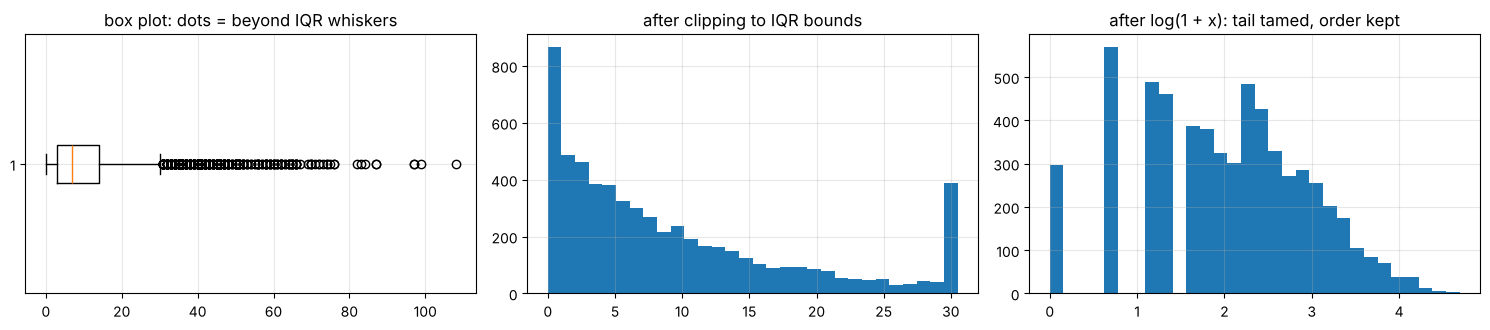

In [20]:
# 🐍 Pure Python IQR rule (quantiles by linear interpolation, like NumPy's default)
def quantile_python(values, q):
    v = sorted(x for x in values if x == x); pos = (len(v) - 1) * q
    lo = int(pos); frac = pos - lo
    return v[lo] + (v[min(lo + 1, len(v) - 1)] - v[lo]) * frac

def iqr_bounds_python(values, k=1.5):
    q1, q3 = quantile_python(values, 0.25), quantile_python(values, 0.75)
    return q1 - k * (q3 - q1), q3 + k * (q3 - q1)

lo, hi = iqr_bounds_python(df["last_login_days_ago"].tolist())
print(f"pure Python IQR bounds: [{lo:.1f}, {hi:.1f}]")

# 🔢 NumPy
x = df["last_login_days_ago"].to_numpy(float)
q1, q3 = np.percentile(x, [25, 75]); lo_np, hi_np = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
z = (x - x.mean()) / x.std()
print(f"NumPy IQR bounds:       [{lo_np:.1f}, {hi_np:.1f}] → {np.sum((x < lo_np) | (x > hi_np))} outliers;  z-score > 3 → {np.sum(np.abs(z) > 3)} outliers")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
ax[0].boxplot(x, orientation="horizontal"); ax[0].set_title("box plot: dots = beyond IQR whiskers")
ax[1].hist(np.clip(x, lo_np, hi_np), bins=30); ax[1].set_title("after clipping to IQR bounds")
ax[2].hist(np.log1p(x), bins=30); ax[2].set_title("after log(1 + x): tail tamed, order kept")
plt.tight_layout(); plt.show()

Here the long tail is real (and predictive — long-absent customers churn), so a **log transform** is better than clipping: it keeps the ordering but stops extreme values from dominating.

## 6. Encoding categorical features

Models need numbers. Three main encodings:

| Encoding | How | Use when |
|---|---|---|
| **One-hot** | one 0/1 column per category | categories have no order (region, payment method). The default. |
| **Ordinal** | map to 0, 1, 2… in a meaningful order | categories *have* an order (basic < standard < premium; contract length) |
| **Target encoding** | replace each category with the mean target for that category | many categories (e.g. 10,000 zip codes) where one-hot would explode |

Never ordinal-encode unordered categories for linear models: `north=0, south=1, east=2` tells the model east is "twice" south.

In [21]:
# 🐍 Pure Python one-hot: learn the categories on training data, then map
def one_hot_fit_python(values):
    return sorted(set(values))

def one_hot_transform_python(values, categories):
    return [[1 if v == c else 0 for c in categories] for v in values]   # unseen category → all zeros

cats = one_hot_fit_python(df["contract"].tolist())
print(cats); print(one_hot_transform_python(["two-year", "month-to-month", "lifetime"], cats), "← 'lifetime' unseen → all zeros")

# 🔢 pandas
print(pd.get_dummies(df["contract"].head(3), dtype=int))

# 📦 scikit-learn — remembers categories from fit, handles unseen ones safely
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(df[["contract"]])
print(ohe.get_feature_names_out(), ohe.transform(pd.DataFrame({"contract": ["two-year", "lifetime"]})))

ordenc = OrdinalEncoder(categories=[["month-to-month", "one-year", "two-year"]]).fit(df[["contract"]])
print("ordinal:", ordenc.transform(pd.DataFrame({"contract": ["month-to-month", "two-year"]})).ravel())

['month-to-month', 'one-year', 'two-year']
[[0, 0, 1], [1, 0, 0], [0, 0, 0]] ← 'lifetime' unseen → all zeros
   month-to-month  two-year
0               1         0
1               0         1
2               0         1
['contract_month-to-month' 'contract_one-year' 'contract_two-year'] [[0. 0. 1.]
 [0. 0. 0.]]
ordinal: [0. 2.]


### Target encoding — powerful, and a leakage trap
If each row's own label is included when computing its category's mean, the encoding partly *contains the answer*. For rare categories it can contain it almost entirely. Fixes:
1. **Out-of-fold encoding:** compute each row's value from the *other* folds only.
2. **Smoothing:** blend the category mean with the global mean, weighted by how many rows the category has: $\text{enc} = \frac{n \cdot \bar y_{\text{cat}} + m \cdot \bar y}{n + m}$.

Demo: a column of **pure random IDs** (500 categories, no real signal):

In [22]:
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.linear_model import LogisticRegression

def target_encode_naive(cat, y):
    means = pd.Series(y).groupby(cat).mean()
    return cat.map(means).to_numpy()

def target_encode_oof(cat, y, k=5, m=10, seed=0):
    """🔢 Out-of-fold + smoothed target encoding."""
    out = np.zeros(len(y)); prior = y.mean()
    for tr, va in KFold(k, shuffle=True, random_state=seed).split(cat):
        stats = pd.DataFrame({"c": cat.iloc[tr].to_numpy(), "y": y[tr]}).groupby("c")["y"].agg(["sum", "count"])
        enc = (stats["sum"] + m * prior) / (stats["count"] + m)
        out[va] = cat.iloc[va].map(enc).fillna(prior).to_numpy()
    return out

rng = np.random.default_rng(1)
y_all = df["churned"].to_numpy()
random_ids = pd.Series(rng.integers(0, 500, len(df)).astype(str))
for name, enc in [("naive", target_encode_naive(random_ids, y_all)), ("out-of-fold + smoothing", target_encode_oof(random_ids, y_all))]:
    auc = cross_val_score(LogisticRegression(), enc.reshape(-1, 1), y_all, cv=5, scoring="roc_auc").mean()
    print(f"{name:25s} CV AUC on a meaningless column = {auc:.3f}")
print("→ AUC 0.5 = no signal. The naive version invents signal that doesn't exist. (sklearn ≥1.3 has TargetEncoder, which does cross-fitting for you.)")

naive                     CV AUC on a meaningless column = 0.693
out-of-fold + smoothing   CV AUC on a meaningless column = 0.516
→ AUC 0.5 = no signal. The naive version invents signal that doesn't exist. (sklearn ≥1.3 has TargetEncoder, which does cross-fitting for you.)


## 7. Feature scaling

| Scaler | Formula | Notes |
|---|---|---|
| **StandardScaler** | $(x - \mu)/\sigma$ | mean 0, std 1. The default. |
| **MinMaxScaler** | $(x - \min)/(\max - \min)$ | squeezes into [0, 1]; one outlier squashes everyone else |
| **RobustScaler** | $(x - \text{median})/\text{IQR}$ | ignores extremes — good with outliers |

**Who needs scaling?** Anything using distances or gradients or penalties: linear/logistic regression with regularisation, SVM, KNN, K-Means, PCA, neural networks. **Trees and tree ensembles don't** — a split "x < 5" works the same at any scale.

pure Python == NumPy == sklearn: True True


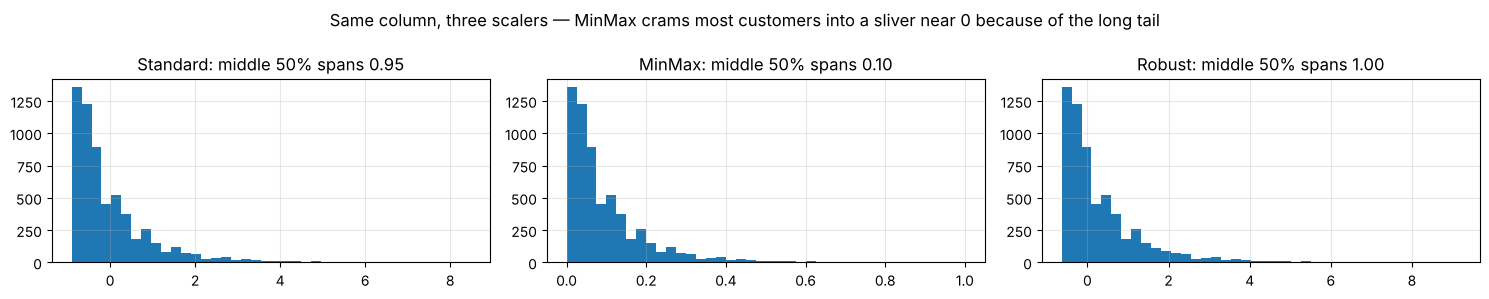

In [23]:
x = df["last_login_days_ago"].to_numpy(float)

# 🐍 Pure Python standard scaler
mu = sum(x) / len(x); sd = (sum((v - mu) ** 2 for v in x) / len(x)) ** 0.5
std_py = [(v - mu) / sd for v in x]

# 🔢 NumPy versions of all three
std_np = (x - x.mean()) / x.std()
mm_np = (x - x.min()) / (x.max() - x.min())
q1, med, q3 = np.percentile(x, [25, 50, 75]); rob_np = (x - med) / (q3 - q1)

# 📦 scikit-learn
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
print("pure Python == NumPy == sklearn:", np.allclose(std_py, std_np), np.allclose(std_np, StandardScaler().fit_transform(x.reshape(-1, 1)).ravel()))

fig, axes = plt.subplots(1, 3, figsize=(15, 3))
for ax, (name, v) in zip(axes, [("Standard", std_np), ("MinMax", mm_np), ("Robust", rob_np)]):
    ax.hist(v, bins=40); ax.set_title(f"{name}: middle 50% spans {np.percentile(v, 75) - np.percentile(v, 25):.2f}")
plt.suptitle("Same column, three scalers — MinMax crams most customers into a sliver near 0 because of the long tail")
plt.tight_layout(); plt.show()

## 8. Feature engineering

Creating informative features is often worth more than switching models. Ideas, with examples from this data:
- **Ratios:** `total_charges / (tenure + 1)` → average actual spend per month.
- **Flags from domain knowledge:** `is_new_customer = tenure < 6` (new customers are fragile).
- **Missing indicators:** `satisfaction_missing` (we saw it's predictive).
- **Transforms:** `log(1 + last_login_days_ago)` for skewed counts.
- **Interactions:** `high_price AND new` (our data truly contains this effect — linear models can't find it without help; trees can).
- **Dates:** day of week, month, "days since" — never the raw timestamp.

In [24]:
df_fe = df.copy()
df_fe["charges_per_month_of_tenure"] = df_fe["total_charges"] / (df_fe["tenure_months"] + 1)
df_fe["is_new_customer"] = (df_fe["tenure_months"] < 6).astype(int)
df_fe["satisfaction_missing"] = df_fe["satisfaction_score"].isna().astype(int)
df_fe["log_last_login"] = np.log1p(df_fe["last_login_days_ago"])
df_fe["pricey_and_new"] = ((df_fe["monthly_charges"] > 80) & (df_fe["tenure_months"] < 12)).astype(int)
print(df_fe.groupby(["is_new_customer", "pricey_and_new"])["churned"].agg(["mean", "count"]).round(3))

                                 mean  count
is_new_customer pricey_and_new              
0               0               0.244   5102
                1               0.590    161
1               0               0.396    593
                1               0.632    144


## 9. Putting it together: a leak-proof Pipeline

All the "learned" steps — imputation medians, scaler means, one-hot categories — must be **fit on training data only**. Doing it by hand is error-prone. scikit-learn's tools make it automatic:
- **`ColumnTransformer`**: apply different preprocessing to different columns.
- **`Pipeline`**: chain preprocessing + model into one object with `.fit` / `.predict`. In cross-validation, the *whole* pipeline is refit inside each fold.

```
                      ┌─ numeric cols ──► impute median (+indicator) ─► scale ─┐
raw DataFrame ──────► ├─ ordered cats ──► ordinal encode ──────────────────────┼─► model
                      └─ other cats ────► impute most-frequent ─► one-hot ─────┘
```

In [25]:
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer

numeric = ["age", "monthly_charges", "tenure_months", "total_charges", "support_calls", "avg_session_minutes",
           "satisfaction_score", "charges_per_month_of_tenure", "is_new_customer", "log_last_login", "pricey_and_new"]
ordered = ["plan", "contract"]
nominal = ["region", "payment_method", "has_partner"]

preprocess = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), numeric),
    ("ord", OrdinalEncoder(categories=[["basic", "standard", "premium"], ["month-to-month", "one-year", "two-year"]]), ordered),
    ("nom", make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")), nominal),
])
model = Pipeline([("prep", preprocess), ("clf", LogisticRegression(max_iter=2000))])

X = df_fe.drop(columns="churned"); y = df_fe["churned"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)
model.fit(X_train, y_train)
from sklearn.metrics import roc_auc_score
print(f"test AUC: {roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]):.3f}")
print("features after preprocessing:", len(model.named_steps["prep"].get_feature_names_out()))
model

test AUC: 0.825
features after preprocessing: 27


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](18,)","['age','region','plan',...,'satisfaction_missing','log_last_login', 'pricey_and_new']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,18
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('ord', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough

In [26]:
# 🐍 What a ColumnTransformer + Pipeline does, written out by hand (simplified) — no magic
class TinyPipeline:
    def __init__(self, num_cols, cat_cols, model):
        self.num_cols, self.cat_cols, self.model = num_cols, cat_cols, model
    def _transform(self, X):
        parts = []
        for c in self.num_cols:                                           # impute + scale with TRAIN statistics
            v = X[c].fillna(self.medians[c]).to_numpy(float)
            parts.append(((v - self.means[c]) / self.stds[c])[:, None])
        for c in self.cat_cols:                                           # one-hot with TRAIN categories
            parts.append(np.array([[1.0 if v == k else 0.0 for k in self.cats[c]] for v in X[c]]))
        return np.hstack(parts)
    def fit(self, X, y):
        self.medians = {c: X[c].median() for c in self.num_cols}         # ← learned from training data only
        filled = {c: X[c].fillna(self.medians[c]) for c in self.num_cols}
        self.means = {c: filled[c].mean() for c in self.num_cols}
        self.stds = {c: filled[c].std(ddof=0) for c in self.num_cols}
        self.cats = {c: sorted(X[c].dropna().unique()) for c in self.cat_cols}
        self.model.fit(self._transform(X), y)
        return self
    def predict_proba(self, X):
        return self.model.predict_proba(self._transform(X))

tiny = TinyPipeline(numeric, ordered + nominal, LogisticRegression(max_iter=2000)).fit(X_train, y_train)
print(f"hand-made pipeline test AUC: {roc_auc_score(y_test, tiny.predict_proba(X_test)[:, 1]):.3f}")

hand-made pipeline test AUC: 0.823


## 10. A data-preparation checklist
1. **Look** at shape, types, `describe()`, value counts, and a sample of rows.
2. **Remove duplicates**; check IDs for repeats.
3. **Fix types** (numbers as text, dates as text); understand *why* values are odd.
4. **Standardise categories** (case, whitespace, synonyms).
5. **Mark impossible values as missing** instead of deleting rows.
6. **Hunt leakage:** for each column, "would I know this at prediction time?"
7. **Explore** the target, distributions, and feature–target relationships.
8. **Decide** missing-value, outlier, encoding and scaling strategies per column.
9. **Engineer features** from domain knowledge.
10. **Put every learned step in a Pipeline**, fit on training data only.

The cleaning steps from this notebook are saved as functions in **`churn_utils.py`** (`clean`, `add_features`, `load_clean`), which notebooks 09–11 import.

## Exercises
1. Plot churn rate by `age` in 10-year bins. Is age a driver?
2. Replace `LogisticRegression` in the pipeline with `HistGradientBoostingClassifier` (trees need no imputing or scaling). Which wins with default settings?
3. Add `TargetEncoder` (from `sklearn.preprocessing`) for `payment_method` instead of one-hot. Compare CV AUC.
4. Check that `churn_utils.clean(raw)` gives the same result as the step-by-step cleaning in this notebook.

In [27]:
# Exercise 4 — solution
from churn_utils import clean
mine = df.reset_index(drop=True)
theirs = clean(raw)
print("same shape:", mine.shape == theirs.shape, "| identical values:", mine.equals(theirs[mine.columns]))

same shape: True | identical values: True


In [28]:
# Exercise 2 — solution
from sklearn.ensemble import HistGradientBoostingClassifier
tree_prep = ColumnTransformer([("num", "passthrough", numeric),                       # trees: no imputing or scaling needed
                               ("cat", OrdinalEncoder(), ordered + nominal)])
hgb = Pipeline([("prep", tree_prep), ("clf", HistGradientBoostingClassifier(random_state=0))])
for name, pipe in [("logistic regression", model), ("gradient boosting", hgb)]:
    print(f"{name:20s} CV AUC {cross_val_score(pipe, X_train, y_train, cv=5, scoring='roc_auc').mean():.3f}")
print("A lesson in itself: with good engineered features, a simple linear model can match or beat an UNTUNED")
print("boosting model. Notebook 11 shows how tuning (learning rate, depth, early stopping) changes that.")

logistic regression  CV AUC 0.813


gradient boosting    CV AUC 0.796
A lesson in itself: with good engineered features, a simple linear model can match or beat an UNTUNED
boosting model. Notebook 11 shows how tuning (learning rate, depth, early stopping) changes that.


**Next:** [09 · An End-to-End ML Project](09_end_to_end_project.ipynb) — from this cleaned data to a tuned, saved, ready-to-use model.

*Going deeper / interview prep:* `ML_Interview_Notes.md` §2.3 (leakage), §2.6 (feature engineering), §2.5 (imbalance) · `ML_System_Design_Notes.md` §2.1–2.4 (data validation, label leakage, point-in-time correctness, training-serving skew) · `Probability_Statistics_Notes.md` §7.3 (multicollinearity).